In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("European_Bank.csv")
print(df.shape)
df.head()
df.info()
df.isnull().sum()          # missing values?
df.duplicated().sum()      # duplicates?
df["Exited"].value_counts(normalize=True)   # churn rate

(10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

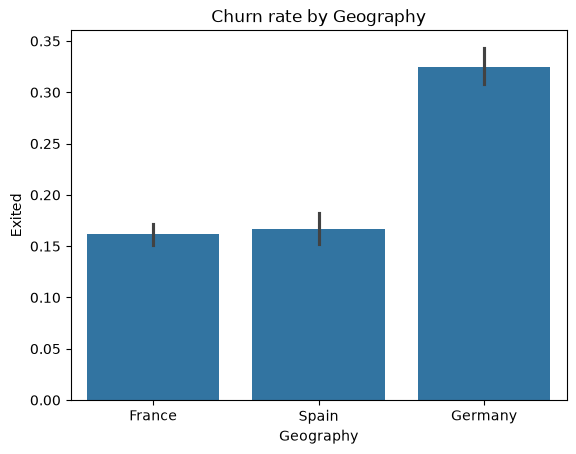

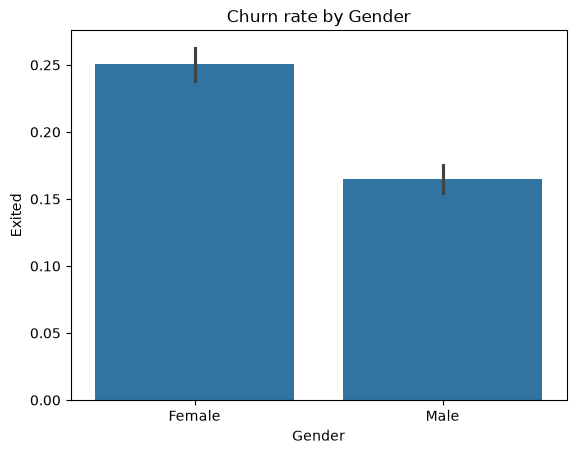

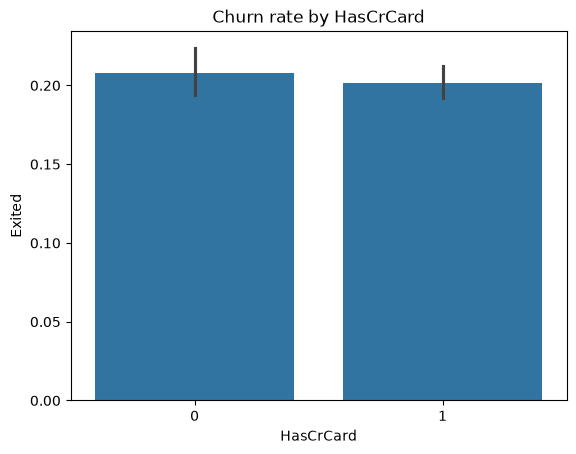

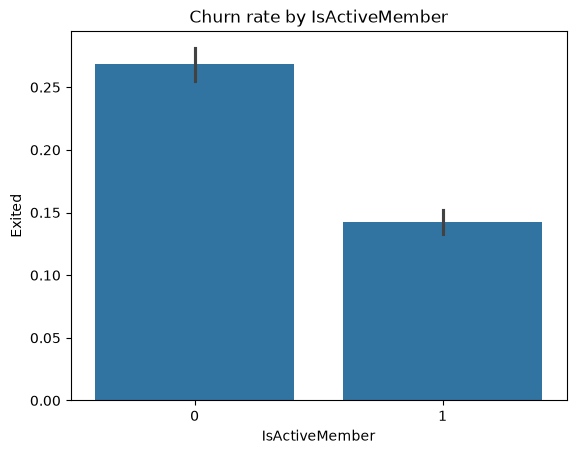

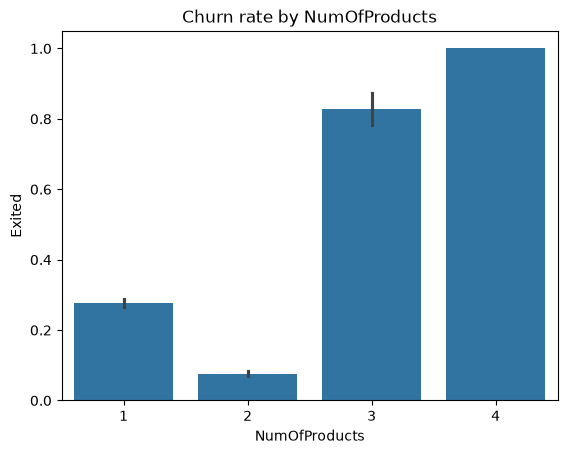

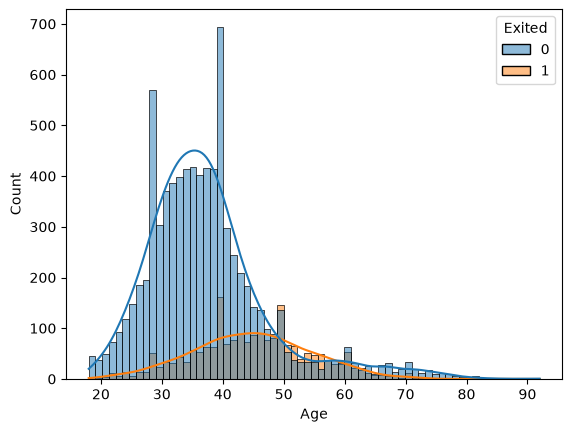

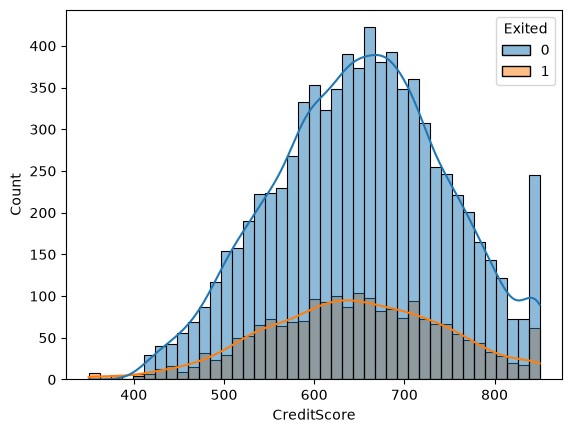

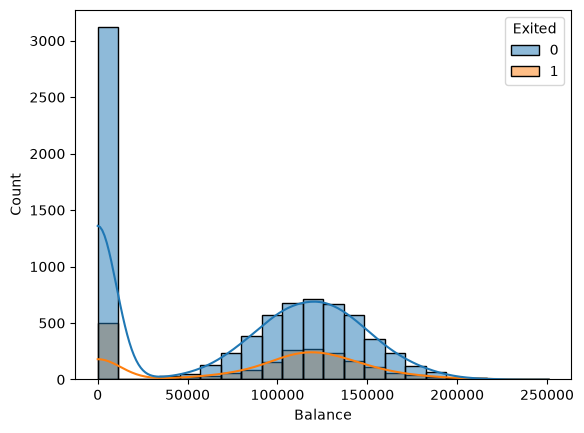

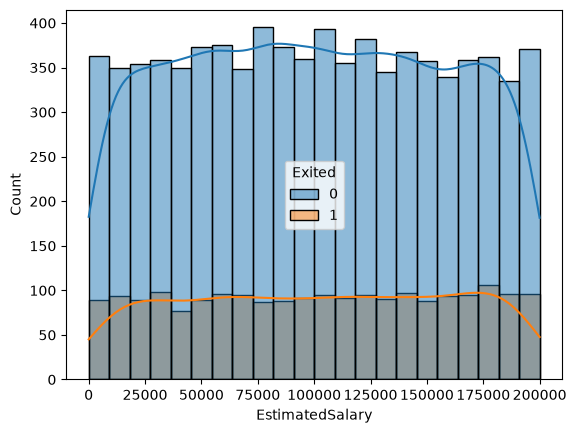

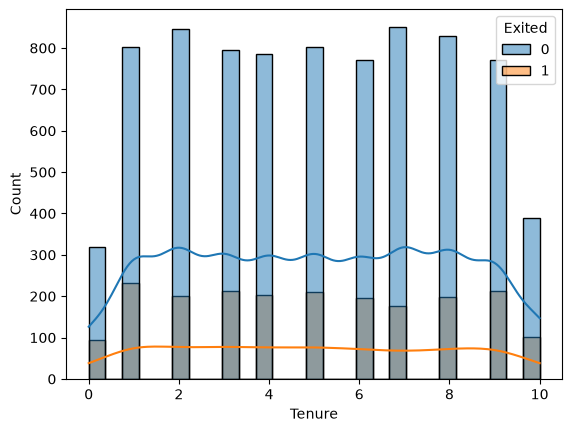

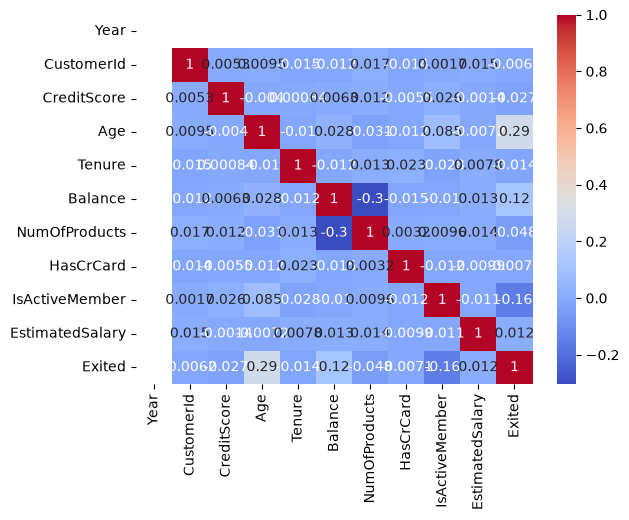

In [2]:
# Churn by category
for col in ["Geography", "Gender", "HasCrCard", "IsActiveMember", "NumOfProducts"]:
    sns.barplot(data=df, x=col, y="Exited"); plt.title(f"Churn rate by {col}"); plt.show()

# Distributions by churn
for col in ["Age", "CreditScore", "Balance", "EstimatedSalary", "Tenure"]:
    sns.histplot(data=df, x=col, hue="Exited", kde=True); plt.show()

# Correlation heatmap
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm"); plt.show()

In [3]:
df = df.drop(columns=["CustomerId", "Surname"], errors="ignore")
df = df.drop(columns=["RowNumber"], errors="ignore")   # if present
df = df.dropna()  # or fill if you found missing values

In [4]:
df["BalanceSalaryRatio"] = df["Balance"] / (df["EstimatedSalary"] + 1)
df["ProductDensity"]     = df["NumOfProducts"] / (df["Tenure"] + 1)
df["EngagementProduct"]  = df["IsActiveMember"] * df["NumOfProducts"]
df["AgeTenure"]          = df["Age"] * df["Tenure"]

In [5]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [6]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

X = df.drop(columns="Exited"); y = df["Exited"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

cat = ["Geography", "Gender"]
num = [c for c in X.columns if c not in cat]
prep = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat),
    ("num", StandardScaler(), num)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, eval_metric="logloss", random_state=42),
}
pipes = {n: Pipeline([("prep", prep), ("model", m)]).fit(X_train, y_train)
         for n, m in models.items()}

In [7]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)

rows = []
for n, p in pipes.items():
    prob = p.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    rows.append([n, accuracy_score(y_test, pred), precision_score(y_test, pred),
                 recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob)])
results = pd.DataFrame(rows, columns=["Model","Accuracy","Precision","Recall","F1","ROC-AUC"]).round(3)
results.sort_values("ROC-AUC", ascending=False)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
3,Gradient Boosting,0.869,0.787,0.489,0.603,0.868
2,Random Forest,0.840,0.608,0.600,0.604,0.855
4,XGBoost,0.858,0.737,0.474,0.577,0.852
1,Decision Tree,0.769,0.459,0.764,0.574,0.834
0,Logistic Regression,0.710,0.383,0.698,0.494,0.776


In [8]:
import joblib
best = pipes["Gradient Boosting"]   # replace with your winner
joblib.dump(best, "model.joblib")

['model.joblib']

In [9]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


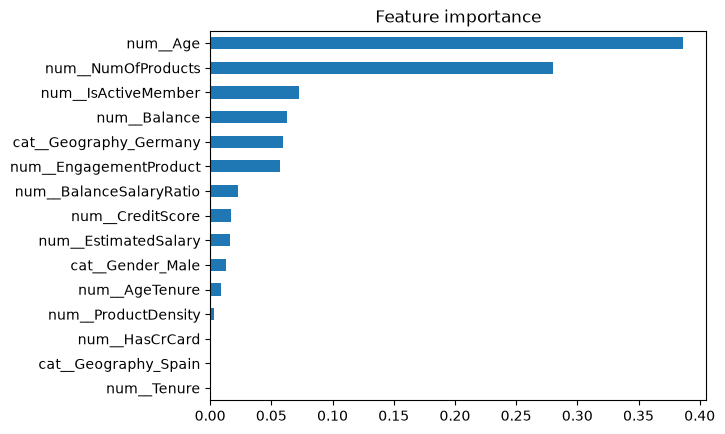

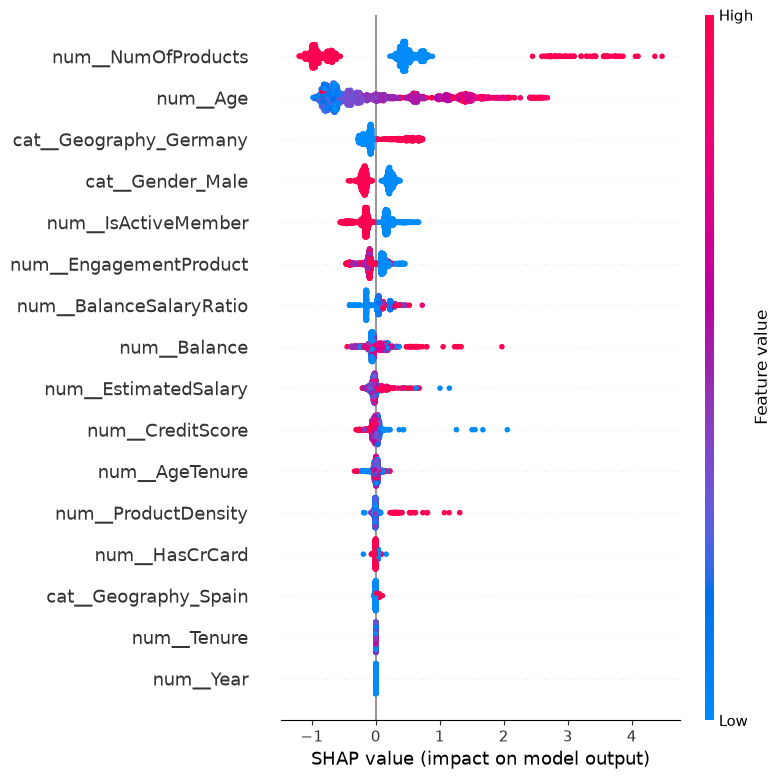

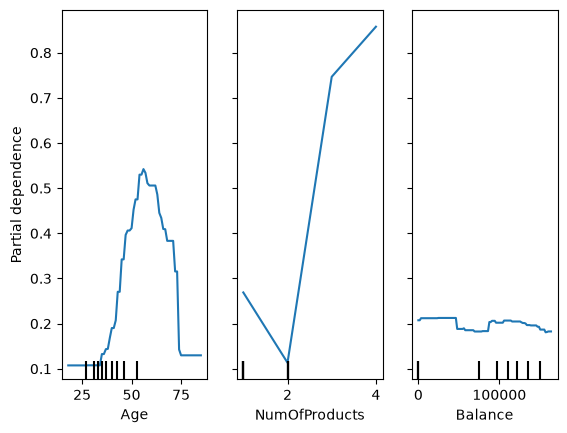

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import shap
from sklearn.inspection import PartialDependenceDisplay

# 1. Feature importance (tree-based model)
names = best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best.named_steps["model"].feature_importances_, index=names).sort_values()
imp.tail(15).plot(kind="barh")
plt.title("Feature importance")
plt.show()

# 2. SHAP
Xt = best.named_steps["prep"].transform(X_test)
Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
explainer = shap.TreeExplainer(best.named_steps["model"])
sv = explainer.shap_values(Xt)
sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, Xt, feature_names=names)

# 3. Partial dependence (integer columns converted to float first)
Xf = X_test.copy()
int_cols = Xf.select_dtypes("int").columns
Xf[int_cols] = Xf[int_cols].astype(float)
PartialDependenceDisplay.from_estimator(best, Xf, ["Age", "NumOfProducts", "Balance"])
plt.show()

In [11]:
for v in ["df", "X_test", "y_test", "pipes", "best"]:
    print(v, v in globals())

df True
X_test True
y_test True
pipes True
best True


In [12]:
best = pipes["Gradient Boosting"]   # use the name of your best model

In [13]:
import pandas as pd, numpy as np, joblib, os
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

# Load and clean
df = pd.read_csv("European_Bank.csv")
df = df.drop(columns=["Year", "CustomerId", "Surname", "RowNumber"], errors="ignore")

# Feature engineering
df["BalanceSalaryRatio"] = df["Balance"] / (df["EstimatedSalary"] + 1)
df["ProductDensity"]     = df["NumOfProducts"] / (df["Tenure"] + 1)
df["EngagementProduct"]  = df["IsActiveMember"] * df["NumOfProducts"]
df["AgeTenure"]          = df["Age"] * df["Tenure"]

# Split
X = df.drop(columns="Exited"); y = df["Exited"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Preprocessing
cat = ["Geography", "Gender"]
num = [c for c in X.columns if c not in cat]
prep = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat),
    ("num", StandardScaler(), num)])

# Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, eval_metric="logloss", random_state=42),
}
pipes = {n: Pipeline([("prep", prep), ("model", m)]).fit(X_train, y_train)
         for n, m in models.items()}

# Pick best and save
best = pipes["Gradient Boosting"]
joblib.dump(best, "model.joblib")

probs = best.predict_proba(X_test)[:, 1]
pd.DataFrame({"prob": probs, "actual": y_test.values}).to_csv("test_probs.csv", index=False)

print("AUC:", round(roc_auc_score(y_test, probs), 3))
print("Saved files in:", os.getcwd())

AUC: 0.869
Saved files in: C:\Users\hello\Desktop\UM\Churn Project


In [14]:
print(X_train.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenure']


In [15]:
import pandas as pd, numpy as np, joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier

# 1. Load
df = pd.read_csv(r"C:\Users\hello\Desktop\UM\Churn Project\European_Bank.csv")
print("Original columns:", df.columns.tolist())

# 2. Clean
df = df.drop(columns=["CustomerId", "Surname", "RowNumber", "Year"], errors="ignore")
df = df.dropna()

# 3. Feature engineering
df["BalanceSalaryRatio"] = df["Balance"] / (df["EstimatedSalary"] + 1)
df["ProductDensity"]     = df["NumOfProducts"] / (df["Tenure"] + 1)
df["EngagementProduct"]  = df["IsActiveMember"] * df["NumOfProducts"]
df["AgeTenure"]          = df["Age"] * df["Tenure"]

# 4. Split
X = df.drop(columns="Exited"); y = df["Exited"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Model columns:", X_train.columns.tolist())

# 5. Train
cat = ["Geography", "Gender"]
num = [c for c in X.columns if c not in cat]
prep = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat),
    ("num", StandardScaler(), num)])
best = Pipeline([("prep", prep), ("model", GradientBoostingClassifier(random_state=42))])
best.fit(X_train, y_train)

# 6. Save model and test probabilities
joblib.dump(best, r"C:\Users\hello\Desktop\UM\Churn Project\model.joblib")
probs = best.predict_proba(X_test)[:, 1]
pd.DataFrame({"prob": probs, "actual": y_test.values}).to_csv(
    r"C:\Users\hello\Desktop\UM\Churn Project\test_probs.csv", index=False)
print("Saved. Test accuracy:", round(best.score(X_test, y_test), 3))

Original columns: ['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
Model columns: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenure']
Saved. Test accuracy: 0.869


In [16]:
print(X_train.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenure']


In [17]:
import joblib
m = joblib.load(r"C:\Users\hello\Desktop\UM\Churn Project\model.joblib")
print(m.named_steps["prep"].feature_names_in_.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenure']


In [18]:
best = pipes["Gradient Boosting"]   # or your best model's name
print(best.named_steps["prep"].feature_names_in_.tolist())   # must show 14 columns
joblib.dump(best, r"C:\Users\hello\Desktop\UM\Churn Project\model.joblib")

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenure']


['C:\\Users\\hello\\Desktop\\UM\\Churn Project\\model.joblib']

In [19]:
import joblib

best = pipes["Gradient Boosting"]   # or your best model's name
print(best.named_steps["prep"].feature_names_in_.tolist())   # must show 14 columns
joblib.dump(best, r"C:\Users\hello\Desktop\UM\Churn Project\model.joblib")
print("saved")

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenure']
saved


In [20]:
import pandas as pd
probs = best.predict_proba(X_test)[:, 1]
pd.DataFrame({"prob": probs, "actual": y_test.values}).to_csv(
    r"C:\Users\hello\Desktop\UM\Churn Project\test_probs.csv", index=False)
print("probs saved")

probs saved


In [22]:
import joblib
m = joblib.load(r"C:\Users\hello\Desktop\UM\Churn Project\model.joblib")
print(m.named_steps["prep"].feature_names_in_.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenure']


In [23]:
print(X_train.columns.tolist())
print("Year" in df.columns)

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenure']
False


In [24]:



df = df.drop(columns=["Year"], errors="ignore")

In [25]:
best = pipes["Gradient Boosting"]
print(best.named_steps["prep"].feature_names_in_.tolist())   # must have NO 'Year'
joblib.dump(best, r"C:\Users\hello\Desktop\UM\Churn Project\model.joblib")
print("saved")

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenure']
saved


In [26]:
import pandas as pd, joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier

path = r"C:\Users\hello\Desktop\UM\Churn Project"
df = pd.read_csv(path + r"\European_Bank.csv")
df = df.drop(columns=["Year", "CustomerId", "Surname", "RowNumber"], errors="ignore").dropna()

df["BalanceSalaryRatio"] = df["Balance"] / (df["EstimatedSalary"] + 1)
df["ProductDensity"]     = df["NumOfProducts"] / (df["Tenure"] + 1)
df["EngagementProduct"]  = df["IsActiveMember"] * df["NumOfProducts"]
df["AgeTenure"]          = df["Age"] * df["Tenure"]

X = df.drop(columns="Exited"); y = df["Exited"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

cat = ["Geography", "Gender"]
num = [c for c in X.columns if c not in cat]
prep = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat),
    ("num", StandardScaler(), num)])
best = Pipeline([("prep", prep), ("model", GradientBoostingClassifier(random_state=42))])
best.fit(X_train, y_train)

joblib.dump(best, path + r"\model.joblib")
pd.DataFrame({"prob": best.predict_proba(X_test)[:, 1], "actual": y_test.values}).to_csv(
    path + r"\test_probs.csv", index=False)

print(best.named_steps["prep"].feature_names_in_.tolist())
print("Year" in best.named_steps["prep"].feature_names_in_)   # must print False

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ProductDensity', 'EngagementProduct', 'AgeTenure']
False


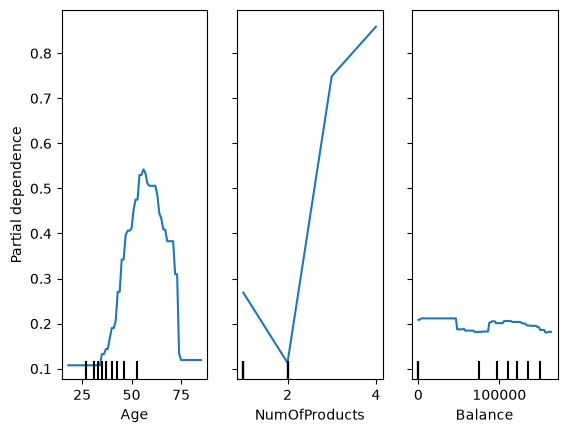

In [27]:
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

Xf = X_test.copy()
Xf[Xf.select_dtypes("int").columns] = Xf.select_dtypes("int").astype(float)
PartialDependenceDisplay.from_estimator(best, Xf, ["Age", "NumOfProducts", "Balance"])
plt.show()

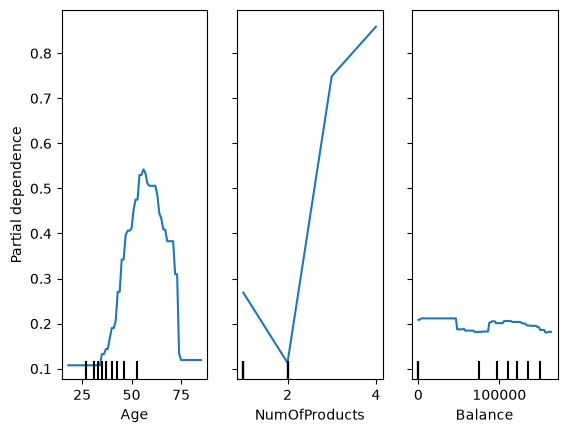

In [28]:
import matplotlib.pyplot as plt
fig = PartialDependenceDisplay.from_estimator(best, Xf, ["Age", "NumOfProducts", "Balance"])
fig.figure_.savefig("partial_dependence.png", dpi=150, bbox_inches="tight")

Rows: 10000 | Churn rate: 0.204

=== MODEL COMPARISON ===
               Model  Accuracy  Precision  Recall    F1  ROC-AUC
  Gradient Boosting     0.869      0.787   0.489 0.603    0.869
      Random Forest     0.845      0.624   0.600 0.612    0.857
            XGBoost     0.858      0.737   0.474 0.577    0.852
      Decision Tree     0.770      0.460   0.767 0.575    0.837
Logistic Regression     0.710      0.383   0.698 0.494    0.776


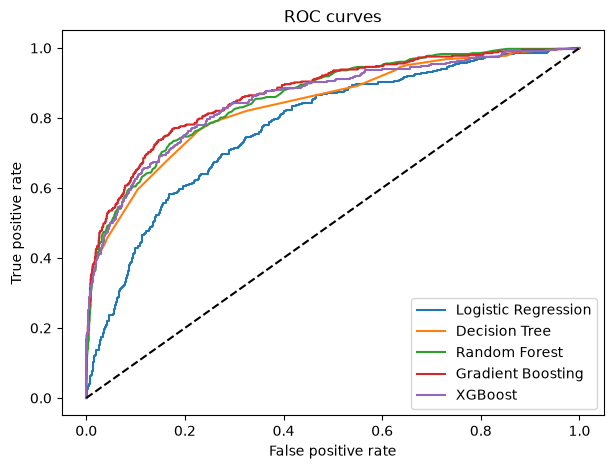


=== THRESHOLD ANALYSIS ===
  Threshold  Precision  Recall    F1
       0.2      0.519   0.771 0.621
       0.3      0.625   0.646 0.635
       0.4      0.699   0.553 0.617
       0.5      0.787   0.489 0.603


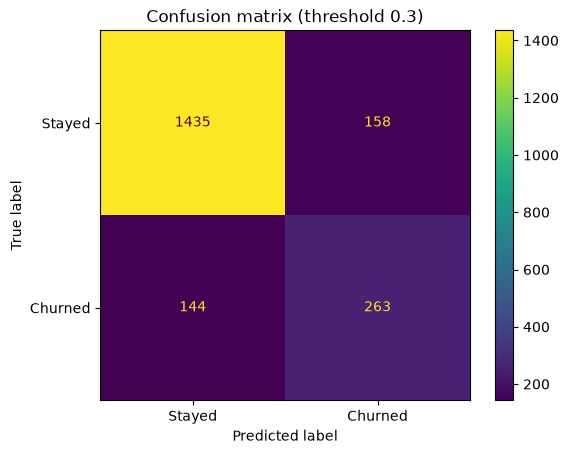

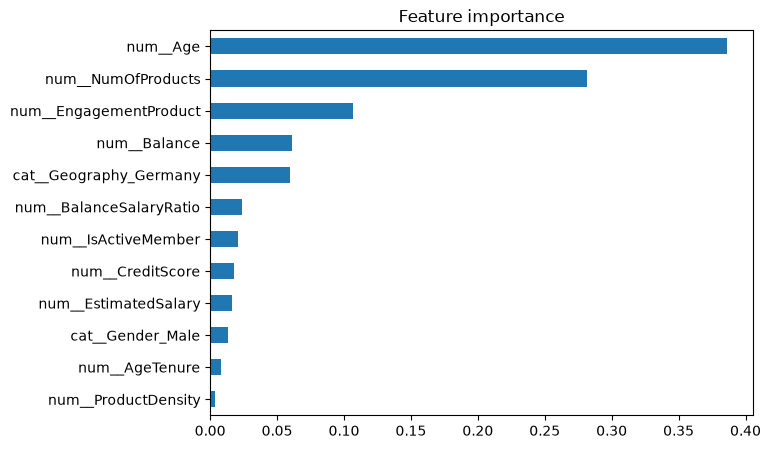


=== TOP 8 FEATURES ===
 num__Age                   0.386
num__NumOfProducts         0.282
num__EngagementProduct     0.107
num__Balance               0.061
cat__Geography_Germany     0.059
num__BalanceSalaryRatio    0.024
num__IsActiveMember        0.021
num__CreditScore           0.018
dtype: float64


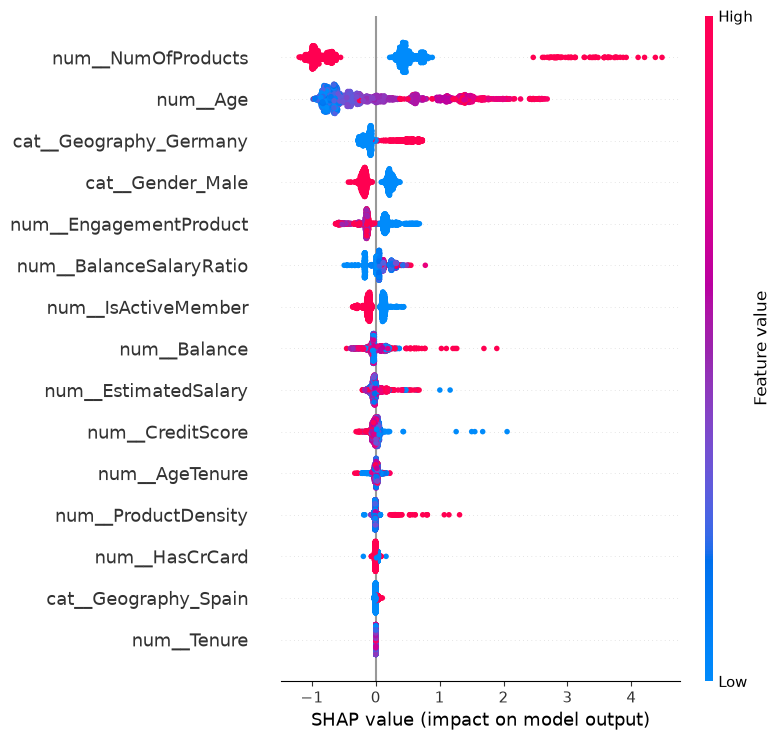

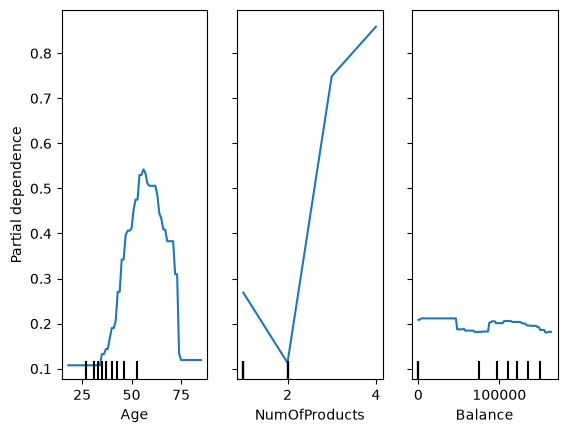


Done. Images and tables are in: C:\Users\hello\Desktop\UM\Churn Project\figures


In [29]:

import pandas as pd, numpy as np, joblib, os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

path = r"C:\Users\hello\Desktop\UM\Churn Project"
os.makedirs(path + r"\figures", exist_ok=True)
fig_dir = path + r"\figures\\"

# ---- data ----
df = pd.read_csv(path + r"\European_Bank.csv")
df = df.drop(columns=["Year", "CustomerId", "Surname", "RowNumber"], errors="ignore").dropna()
df["BalanceSalaryRatio"] = df["Balance"] / (df["EstimatedSalary"] + 1)
df["ProductDensity"]     = df["NumOfProducts"] / (df["Tenure"] + 1)
df["EngagementProduct"]  = df["IsActiveMember"] * df["NumOfProducts"]
df["AgeTenure"]          = df["Age"] * df["Tenure"]
X = df.drop(columns="Exited"); y = df["Exited"]
print("Rows:", len(df), "| Churn rate:", round(y.mean(), 3))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

cat = ["Geography", "Gender"]
num = [c for c in X.columns if c not in cat]
prep = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat),
    ("num", StandardScaler(), num)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, eval_metric="logloss", random_state=42),
}
pipes = {n: Pipeline([("prep", prep), ("model", m)]).fit(X_train, y_train)
         for n, m in models.items()}

# ---- 1. model comparison table ----
rows = []
for n, p in pipes.items():
    prob = p.predict_proba(X_test)[:, 1]; pred = (prob >= 0.5).astype(int)
    rows.append([n, accuracy_score(y_test, pred), precision_score(y_test, pred),
                 recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob)])
results = pd.DataFrame(rows, columns=["Model","Accuracy","Precision","Recall","F1","ROC-AUC"]
                       ).round(3).sort_values("ROC-AUC", ascending=False)
results.to_csv(path + r"\figures\model_comparison.csv", index=False)
print("\n=== MODEL COMPARISON ===\n", results.to_string(index=False))

# ---- 2. ROC curves ----
plt.figure(figsize=(7, 5))
for n, p in pipes.items():
    fpr, tpr, _ = roc_curve(y_test, p.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=n)
plt.plot([0, 1], [0, 1], "k--"); plt.legend()
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves")
plt.savefig(fig_dir + "roc_curves.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- 3. threshold analysis (best model) ----
best = pipes["Gradient Boosting"]       # change if another model wins on ROC-AUC
prob = best.predict_proba(X_test)[:, 1]
th = []
for t in [0.2, 0.3, 0.4, 0.5]:
    pred = (prob >= t).astype(int)
    th.append([t, precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred)])
th = pd.DataFrame(th, columns=["Threshold","Precision","Recall","F1"]).round(3)
th.to_csv(path + r"\figures\threshold_analysis.csv", index=False)
print("\n=== THRESHOLD ANALYSIS ===\n", th.to_string(index=False))

# ---- 4. confusion matrix ----
chosen = 0.3                              # pick the threshold you will defend
ConfusionMatrixDisplay(confusion_matrix(y_test, (prob >= chosen).astype(int)),
                       display_labels=["Stayed", "Churned"]).plot()
plt.title(f"Confusion matrix (threshold {chosen})")
plt.savefig(fig_dir + "confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- 5. feature importance ----
names = best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best.named_steps["model"].feature_importances_, index=names).sort_values()
imp.tail(12).plot(kind="barh", figsize=(7, 5)); plt.title("Feature importance")
plt.savefig(fig_dir + "feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()
print("\n=== TOP 8 FEATURES ===\n", imp.sort_values(ascending=False).head(8).round(3))

# ---- 6. SHAP ----
import shap
Xt = best.named_steps["prep"].transform(X_test)
Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
sv = shap.TreeExplainer(best.named_steps["model"]).shap_values(Xt)
sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, Xt, feature_names=names, show=False)
plt.savefig(fig_dir + "shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- 7. partial dependence ----
from sklearn.inspection import PartialDependenceDisplay
Xf = X_test.copy()
Xf[Xf.select_dtypes("int").columns] = Xf.select_dtypes("int").astype(float)
d = PartialDependenceDisplay.from_estimator(best, Xf, ["Age", "NumOfProducts", "Balance"])
d.figure_.savefig(fig_dir + "partial_dependence.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- 8. keep the app files in sync with this exact model ----
joblib.dump(best, path + r"\model.joblib")
pd.DataFrame({"prob": prob, "actual": y_test.values}).to_csv(path + r"\test_probs.csv", index=False)
print("\nDone. Images and tables are in:", path + r"\figures")

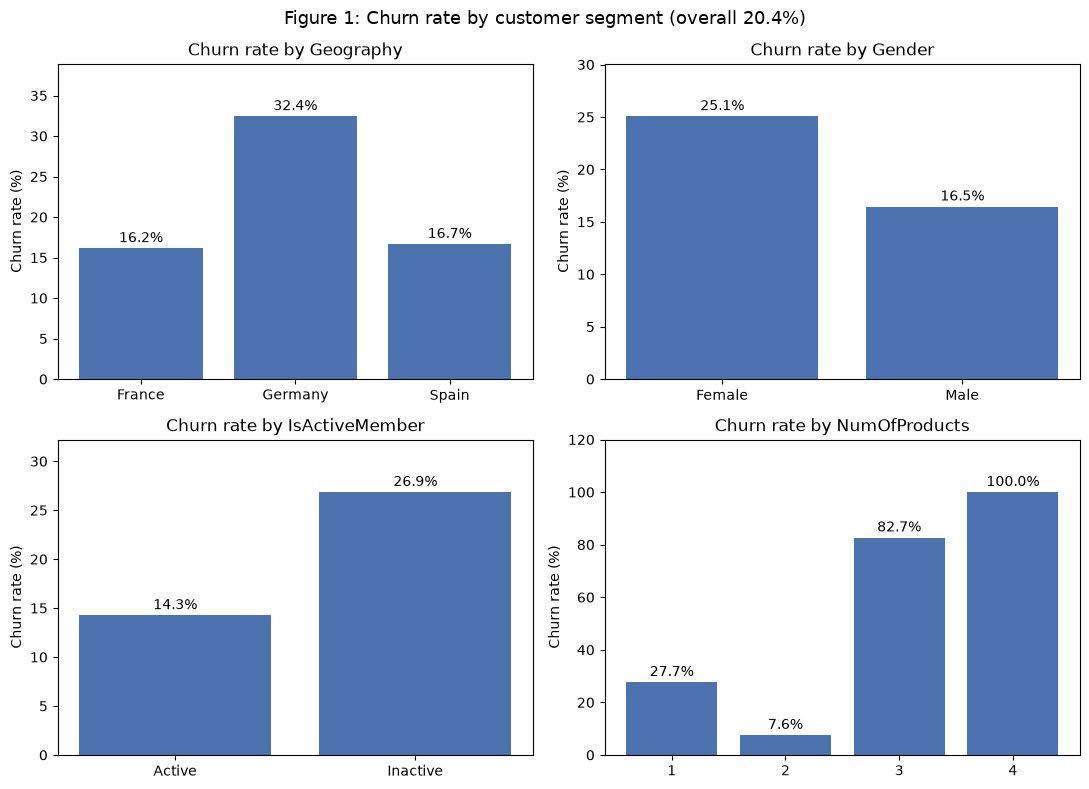

In [30]:
import pandas as pd, matplotlib.pyplot as plt, os

path = r"C:\Users\hello\Desktop\UM\Churn Project"
os.makedirs(path + r"\figures", exist_ok=True)

df = pd.read_csv(path + r"\European_Bank.csv")
df["IsActiveMember"] = df["IsActiveMember"].map({0: "Inactive", 1: "Active"})

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]):
    rates = df.groupby(col)["Exited"].mean() * 100
    bars = ax.bar(rates.index.astype(str), rates.values, color="#4C72B0")
    ax.bar_label(bars, fmt="%.1f%%", padding=2)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, rates.max() * 1.2)
fig.suptitle("Figure 1: Churn rate by customer segment (overall 20.4%)", fontsize=13)
plt.tight_layout()
plt.savefig(path + r"\figures\eda_churn_rates.png", dpi=150, bbox_inches="tight")
plt.show()